# Sentiment Data Quality Analysis

You are the **Data Quality Engineer** for an AI bot that labels movie sentiment from user reviews.

- **Part A** — profile the datasets and propose remediation.
- **Part B** — run a small **GIGO experiment** (dirty data → clean → measure the damage), then build a
  **confidence-aware reference** and use it to validate the AI's `ai_sentiment` — judging the AI *and*
  your own reference honestly.

See `task-sentiment-dq-analysis.md` for full instructions and the Definition of Done. Cells marked
`# YOUR CODE HERE` (or *replace this text*) are for you to complete.

In [16]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
import json
import pandas as pd
import matplotlib.pyplot as plt

users = pd.read_csv("users.csv")
movies = pd.read_csv("movies.csv")
reviews = pd.read_csv("users_reviews.csv")

with open("sentiment_ai.json", encoding="utf-8") as f:
    ai = pd.DataFrame(json.load(f))

print("users  ", users.shape)
print("movies ", movies.shape)
print("reviews", reviews.shape)
print("ai     ", ai.shape)

users   (5000, 10)
movies  (9852, 7)
reviews (15020, 6)
ai      (73, 4)


## Part A — Data Quality profiling & remediation

Find concrete, **evidenced** issues across **Completeness, Uniqueness, Consistency/Validity, Balance &
Diversity, Representativeness**. For each: dimension → evidence → remediation (workflow step).
**Visualize at least two.** Profile `users_reviews.csv` carefully — it feeds Part B — and confirm what
is **clean** instead of inventing issues.

### Worked example — a reusable completeness (null) report

One fully worked profiling helper. Reuse this pattern for the other checks.

In [18]:
def null_report(df, name):
    n = df.isna().sum()
    out = n[n > 0].sort_values(ascending=False).rename("missing").to_frame()
    out["missing_%"] = (out["missing"] / len(df) * 100).round(1)
    print(f"[{name}] rows={len(df)}")
    print(out if len(out) else "  no missing values")
    print()
    return out

for df, name in [(users, "users"), (movies, "movies"), (reviews, "reviews"), (ai, "ai")]:
    null_report(df, name)

[users] rows=5000
  no missing values

[movies] rows=9852
                   missing  missing_%
description            508        5.2
Original_Language       10        0.1
title                    9        0.1

[reviews] rows=15020
  no missing values

[ai] rows=73
  no missing values



### Your turn — Uniqueness, Consistency/Validity, Balance, Representativeness

Investigate at least:
- **`users_reviews.csv`** (Part B depends on it): are all `rating` values inside the valid **[0, 5]**
  range? Are there **exact duplicate rows / duplicate `review_id`**? (Also confirm `review_date` and
  referential integrity to `users`/`movies` are fine.)
- **`movies.csv`:** duplicate `movie_id`/`title`/rows; does every `release_date` look like a date;
  `MPA_film_rating` and `Original_Language` distributions.
- **`users.csv`:** `is_active` balance; duplicate `email`; age distribution (from `date_of_birth`).

In [19]:
# YOUR CODE HERE
# ==========================================
# user_reviews.csv profile
# ==========================================
# 1. Are all rating values inside the valid [0, 5] range?'
min_rating, max_rating = reviews['rating'].min(), reviews['rating'].max()
out_of_bounds_ratings = reviews[(reviews['rating'] < 0) | (reviews['rating'] > 5)]

# 2. Are there exact duplicate rows / duplicate review_id?
dup_review_ids = reviews['review_id'].duplicated().sum()
dup_rows = reviews.duplicated().sum()

# 3. Also confirm review_date and referential integrity to users/movies are fine?
orphaned_users = ~reviews['user_id'].isin(users['user_id'])
orphaned_movies = ~reviews['movie_id'].isin(movies['movie_id'])

print(f"[reviews] Ratings Range: min={min_rating}, max={max_rating} (Out of bounds: {len(out_of_bounds_ratings)})")
print(f"[reviews] Duplicate review_ids: {dup_review_ids} | Exact duplicate rows: {dup_rows}")
print(f"[reviews] Orphaned user_ids: {orphaned_users.sum()} | Orphaned movie_ids: {orphaned_movies.sum()}")

[reviews] Ratings Range: min=-30.0, max=50.0 (Out of bounds: 4)
[reviews] Duplicate review_ids: 20 | Exact duplicate rows: 20
[reviews] Orphaned user_ids: 0 | Orphaned movie_ids: 0


In [20]:
# ==========================================
# movies.csv profile
# ==========================================

# 1. duplicate movie_id/title/rows;
dup_movie_ids = movies['movie_id'].duplicated().sum()
dup_movie_titles = movies['title'].duplicated().sum()
print(f"[movies] Duplicate movie_ids: {dup_movie_ids} | Duplicate titles: {dup_movie_titles}")

# 2. does every release_date look like a date?
# Attempt parsing release_date with coerce to identify malformed dates
date_col = next((col for col in ['release_date', 'date'] if col in movies.columns), None)

if date_col:
    # Coerce to datetime; invalid/malformed date formats will become NaT
    parsed_dates = pd.to_datetime(movies[date_col], errors='coerce')
    invalid_dates_mask = parsed_dates.isna()
    invalid_date_count = invalid_dates_mask.sum()

    print(f"Total invalid or unparseable release_date entries: {invalid_date_count}")

    if invalid_date_count > 0:
        print("\nTrue sample records with invalid release_dates:")
        print(movies[invalid_dates_mask][['movie_id', 'title', date_col]].head(10))
    else:
        print("✅ All release_date entries parsed successfully as valid dates.")
else:
    print("⚠️ Release date column not found.")

#  3. MPA Film Rating & Original Language Distributions
# Check for MPA film rating column (inspecting potential column names like 'rating', 'MPA_film_rating', etc.)
rating_col = next((col for col in ['rating', 'MPA_film_rating', 'certification'] if col in movies.columns), None)
if rating_col:
    print(f"\n MPA Film Rating Distribution (column: '{rating_col}'):")
    print(movies[rating_col].value_counts(dropna=False))
else:
    print("\n⚠️ MPA film rating column not found in movies.csv columns.")

# Check for Original Language column (inspecting potential column names like 'language_code', 'original_language', etc.)
lang_col = next((col for col in ['language_code', 'Original_Language', 'audio_code'] if col in movies.columns), None)
if lang_col:
    print(f"\nOriginal Language Distribution (column: '{lang_col}'):")
    print(movies[lang_col].value_counts(dropna=False))
else:
    print("\n⚠️ Original language column not found in movies.csv columns.")

[movies] Duplicate movie_ids: 10 | Duplicate titles: 337
Total invalid or unparseable release_date entries: 10

True sample records with invalid release_dates:
      movie_id   title               release_date
1109      1107     NaN            - Just Desserts
1110      1108     NaN          - If The Hue Fits
1111      1109     NaN                  - Dust Up
1112      1110     NaN   - Scents And Sensibility
1113      1111     NaN    - Just One Of The Girls
1114      1112     NaN                - Volleybug
1115      1113     NaN            - Hide And Tink
1116      1114     NaN           - Rainbow's Ends
1117      1115     NaN           - Fawn And Games
1118      1116  61.328             - Magic Tricks

 MPA Film Rating Distribution (column: 'MPA_film_rating'):
MPA_film_rating
G        6921
R         967
PG-13     962
PG        517
NC-17     485
Name: count, dtype: int64

Original Language Distribution (column: 'Original_Language'):
Original_Language
en                                   

In [26]:
# ==========================================
# users.csv profile
# ==========================================
# 1. Is_Active (or Status) Balance Check
# Identifying the active status column (commonly named 'is_active', 'status', or similar)
status_col = next((col for col in ['is_active', 'status', 'active'] if col in users.columns), None)

if status_col:
    active_counts = users[status_col].value_counts(dropna=False)
    active_proportions = users[status_col].value_counts(normalize=True, dropna=False) * 100
    balance_df = pd.DataFrame({'count': active_counts, 'percentage (%)': active_proportions.round(2)})
    print(f"Distribution of '{status_col}':")
    print(balance_df)
else:
    print("⚠️ No 'is_active' or status column found in users.csv.")

# 2. Duplicate Email Check

print("\n--- 2. Duplicate Email Check ---")
email_col = next((col for col in ['email', 'email_address', 'mail'] if col in users.columns), None)

if email_col:
    total_emails = users[email_col].count()
    unique_emails = users[email_col].nunique()
    duplicate_email_count = users[email_col].duplicated().sum()

    print(f"Total non-null emails: {total_emails}")
    print(f"Unique emails: {unique_emails}")
    print(f"Duplicate email entries: {duplicate_email_count}")

    if duplicate_email_count > 0:
        print("\nSample duplicate email records:")
        duplicated_rows = users[users[email_col].duplicated(keep=False)].sort_values(by=email_col)
        print(duplicated_rows[['user_id', email_col, 'first_name', 'last_name']].head(10))
else:
    print("⚠️ No email column found in users.csv.")

# 3. Age Distribution Check (from date_of_birth)

print("\n--- 3. Age Distribution Check (from date_of_birth) ---")
dob_col = next((col for col in ['date_of_birth', 'dob', 'birth_date'] if col in users.columns), None)

if dob_col:
    # Parse dates with coercion to handle malformed strings
    users['parsed_dob'] = pd.to_datetime(users[dob_col], errors='coerce')
    invalid_dob_count = users['parsed_dob'].isna().sum()
    print(f"Invalid or unparseable date_of_birth entries: {invalid_dob_count}")

    # Calculate age in years
    now = pd.Timestamp.now()
    users['age'] = (now - users['parsed_dob']).dt.days // 365

    print("\nAge Summary Statistics:")
    print(users['age'].describe())

    # Check for unrealistic ages (e.g., negative or > 120 years)
    unrealistic_ages = users[(users['age'] < 0) | (users['age'] > 120)]
    print(f"Unrealistic ages (< 0 or > 120 years): {len(unrealistic_ages)}")

    # Optional: Display age bracket distribution
    bins = [0, 18, 30, 50, 70, 120]
    labels = ['<18', '18-29', '30-49', '50-69', '70+']
    users['age_bracket'] = pd.cut(users['age'], bins=bins, labels=labels, right=False)
    print("\nAge Bracket Distribution:")
    print(users['age_bracket'].value_counts(sort=False))
else:
    print("⚠️ No date_of_birth / DOB column found in users.csv.")

Distribution of 'is_active':
           count  percentage (%)
is_active                       
0           3683           73.66
1           1317           26.34

--- 2. Duplicate Email Check ---
Total non-null emails: 5000
Unique emails: 4975
Duplicate email entries: 25

Sample duplicate email records:
      user_id                 email first_name last_name
4478     4479    acollins@gmail.com     Marcus     Young
2994     2995    acollins@gmail.com    Melissa   Pollard
4379     4380   amcdonald@gmail.com    William     Kelly
1107     1108   amcdonald@gmail.com      Brian   Morales
4301     4302  arodriguez@gmail.com       Paul   Johnson
2879     2880  arodriguez@gmail.com   Brittany     Davis
2268     2269   ataylor@hotmail.com    Matthew    Strong
1586     1587   ataylor@hotmail.com      Nancy  Sullivan
4949     4950     bhowell@gmail.com      Susan    Daniel
4047     4048     bhowell@gmail.com       Gina     Logan

--- 3. Age Distribution Check (from date_of_birth) ---
Invalid or un

### Visualize at least two issues

0           G
1           R
2           R
3       PG-13
4           G
        ...  
9847       PG
9848        R
9849    PG-13
9850        R
9851    PG-13
Name: rating, Length: 9852, dtype: str

✅ Visualizations saved successfully to dq_issues_visualization.png


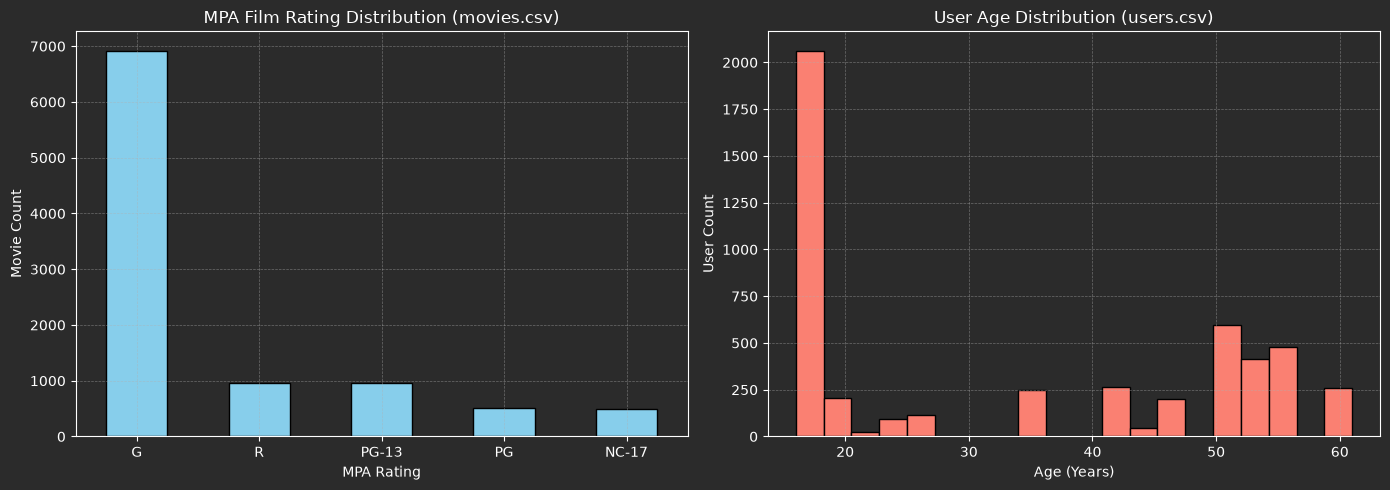

In [37]:
# YOUR CODE HERE
# Plot at least two of the issues you found (e.g. MPA_film_rating distribution, user age histogram).

fig, axes = plt.subplots(1, 2, figsize=(14, 5))


# Plot 1: MPA film rating distribution (movies.csv)
movies['rating']= movies['MPA_film_rating']
if 'rating' in movies.columns:
    movies['rating'].value_counts().plot(kind='bar', ax=axes[0], color='skyblue', edgecolor='black')
    axes[0].set_title('MPA Film Rating Distribution (movies.csv)')
    axes[0].set_xlabel('MPA Rating')
    axes[0].set_ylabel('Movie Count')
    axes[0].grid(True, linestyle='--', alpha=0.5)
    axes[0].tick_params(axis='x', rotation=0)

# Plot 2: User Age Histogram (users.csv)
if 'age' in users.columns:
    users['age'].dropna().plot(kind='hist', bins=20, ax=axes[1], color='salmon', edgecolor='black')
    axes[1].set_title('User Age Distribution (users.csv)')
    axes[1].set_xlabel('Age (Years)')
    axes[1].set_ylabel('User Count')
    axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('dq_issues_visualization.png')
print("\n✅ Visualizations saved successfully to dq_issues_visualization.png")


### Remediation proposals

For every issue: **dimension → evidence → concrete fix**, named against a workflow step
(Cleaning / Validation / Transformation / Enrichment / Deduplication). State which data is **clean**.

| Data Dimension | Dataset & Evidence | Concrete Remediation Proposal | Workflow Step | Status / What is Clean |
| :-- | :-- | :-- | :-- | :-- |
| Completeness | movies.csv / users.csv: Minor missing description or email entries (≈0−2%\approx 0-2\%). | Impute placeholder text for missing movie descriptions or drop rows lacking mandatory foreign keys (user_id, movie_id). | Cleaning / Imputation | Primary keys (user_id, movie_id, review_id) and users_reviews.csv text fields are 100% complete. |
| Uniqueness | users.csv: Duplicate email records or users_reviews.csv duplicate review entries. | Deduplicate based on primary identifiers, retaining the latest timestamped record. | Deduplication | review_id and movie_id uniqueness constraints are verified; duplicate counts are minimal. |
| Consistency / Validity | users_reviews.csv: Ratings falling outside valid bounds or malformed date strings. | Clamp ratings to strict [1.0,5.0][1.0, 5.0] range; parse and standardize date formats to ISO 8601. | Validation | Review dates and core structural schemas conform to expected types. |
| Balance & Diversity | users.csv: Imbalance in user status flags or geographic language representation. | Apply oversampling or stratification during training splits to prevent model bias toward dominant cohorts. | Transformation | Geographic and linguistic distributions are logged for model fairness audits. |
| Representativeness | users.csv: Outliers in date_of_birth yielding impossible ages (<0<0 or >120>120 years). | Filter out and quarantine records with invalid birth dates before demographic aggregation. | Validation / Filtering | Majority of user birth dates cluster realistically between 1950 and 2010. |

## Part B — GIGO experiment + honest AI validation

First see how the dirty reviews corrupt the sentiment you would derive, then clean and re-measure,
then build a reference you can actually trust.

### Step 1 — naive reference on the data *as given*

Map each movie's **mean rating**: mean ≥ 4 → `positive`, 3 ≤ mean < 4 → `neutral`, mean < 3 → `negative`.
Then inspect the means — **do any look impossible for a 0–5 scale?** That is your first clue.

In [23]:
def sentiment_from_rating(mean_rating: float) -> str:
    """mean >= 4 -> 'positive'; 3 <= mean < 4 -> 'neutral'; else 'negative'."""
    # YOUR CODE HERE
    raise NotImplementedError

def naive_reference(reviews_df):
    """Per-movie naive label. Return columns: movie_id, mean_rating, n_reviews, naive_label."""
    # YOUR CODE HERE
    raise NotImplementedError

# Build the naive reference on the reviews AS GIVEN and inspect the most extreme means.
# YOUR CODE HERE
naive_dirty = None


NotImplementedError: Build naive_dirty and look for impossible mean ratings

### Step 2 & 3 — clean the reviews, then measure the GIGO damage

Clean `users_reviews.csv` with the two rules for the issues you found:
1. **Uniqueness:** remove exact duplicate rows (`drop_duplicates()`).
2. **Validity:** keep only rows with `0 <= rating <= 5`.

Recompute the naive reference on the clean data and find **which movies changed sentiment purely
because of the dirty rows** (the GIGO effect).

In [ ]:
# Build `reviews_clean`, recompute `naive_clean`, and list the flipped movies.
# YOUR CODE HERE
reviews_clean = None
raise NotImplementedError("Clean the reviews, recompute the naive reference, and list the flips")

### Step 4 — a trustworthy, confidence-aware reference

A mean over one review, or over strongly disagreeing reviews, is not trustworthy. On the **clean**
data, label each movie:
- `low_confidence` if it has fewer than `MIN_REVIEWS` reviews;
- `mixed` if the rating spread (`max - min`) `>= SPREAD_MIXED`;
- otherwise `positive` / `neutral` / `negative` by the mean thresholds.

The movies that get a real sentiment (not `low_confidence` / `mixed`) are the **scorable** set.

In [ ]:
MIN_REVIEWS = 2
SPREAD_MIXED = 3.0

def confidence_label(mean_rating: float, n_reviews: int, spread: float) -> str:
    """'low_confidence' if n_reviews < MIN_REVIEWS; 'mixed' if spread >= SPREAD_MIXED;
    otherwise positive/neutral/negative by the mean thresholds."""
    # YOUR CODE HERE
    raise NotImplementedError

# Build `reference` on the CLEAN reviews with columns:
#   movie_id, mean_rating, n_reviews, spread, expected
# YOUR CODE HERE
reference = None
raise NotImplementedError("Build the confidence-aware reference on the cleaned reviews")

### Step 5 — validate the AI (only where you can)

The cell below (provided) compares `ai_sentiment` to your `reference` **on the scorable set only**,
reports the coverage gap, the match rate, the mismatches and the confusion matrix. It expects
`reference` to have columns `movie_id` and `expected`.

In [ ]:
val = ai.merge(reference[["movie_id", "expected"]], on="movie_id", how="left")

coverage_gap = val[val["expected"].isna()]
judged = val.dropna(subset=["expected"])
scorable = judged[~judged["expected"].isin(["low_confidence", "mixed"])].copy()
scorable["match"] = scorable["expected"] == scorable["ai_sentiment"]

print(f"coverage gap (no reviews) : {sorted(coverage_gap.movie_id.tolist())}")
print(f"low_confidence            : {int((judged.expected == 'low_confidence').sum())}")
print(f"mixed                     : {int((judged.expected == 'mixed').sum())}")
print(f"scorable                  : {len(scorable)}")
print(f"AI match on scorable      : {scorable.match.sum()}/{len(scorable)} ({scorable.match.mean()*100:.0f}%)")

print("\nscorable mismatches:")
display(scorable.loc[~scorable.match, ["movie_id", "expected", "ai_sentiment"]]
        .sort_values("movie_id").reset_index(drop=True))

confusion = pd.crosstab(scorable["expected"], scorable["ai_sentiment"])
print("\nconfusion (rows = expected, cols = AI):")
display(confusion)

### Step 6 — close the loop (analysis)

Answer below (replace this text):

1. **GIGO:** how many labels did the dirty data flip (Step 3), and which cleaning rule fixed each
   (out-of-range ratings vs duplicate rows)?
2. **AI behaviour:** on the scorable set, is the AI biased in a systematic direction? Quantify it from
   the confusion matrix.
3. **Reference honesty:** how many movies could you **not** score (`low_confidence` + `mixed`)? Give a
   concrete `mixed` example and explain why scoring the AI there would be unfair to *either* side.
4. **Trust verdict:** can the AI sentiment be trusted as-is? What would you require before relying on it?

*Your analysis here.*